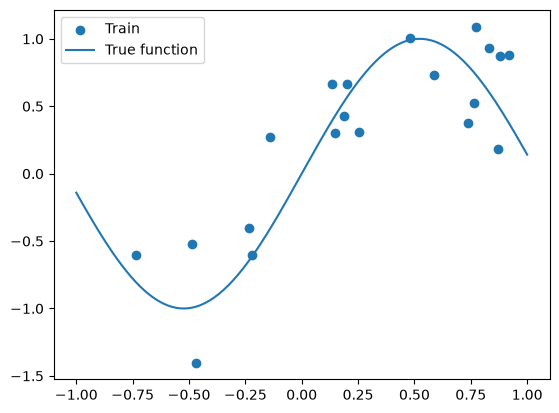

In [7]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Training data: few samples + noise
x_train = torch.rand(20, 1) * 2 - 1
y_train = torch.sin(3 * x_train) + 0.3 * torch.randn(20, 1)

# Validation data: dense samples, without noise
x_val = torch.linspace(-1, 1, 200).unsqueeze(1)
y_val = torch.sin(3 * x_val)

plt.scatter(x_train.numpy(), y_train.numpy(), label="Train")
plt.plot(x_val.numpy(), y_val.numpy(), label="True function")
plt.legend()
plt.show()

In [8]:
# 故意使用较大的网络
class OverfitModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)


model = OverfitModel()

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

In [9]:
train_losses = []
val_losses = []

epochs = 1500

for epoch in range(epochs):
    # Training
    model.train()

    optimizer.zero_grad()

    train_pred = model(x_train)
    train_loss = loss_fn(train_pred, y_train)

    train_loss.backward()
    optimizer.step()

    # Validation
    model.eval()

    with torch.no_grad():
        val_pred = model(x_val)
        val_loss = loss_fn(val_pred, y_val)

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

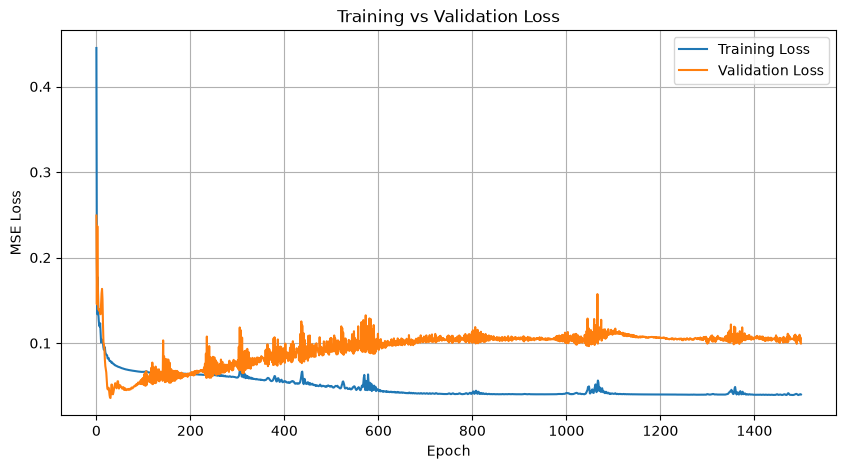

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [11]:
best_epoch = min(
    range(len(val_losses)),
    key=lambda i: val_losses[i]
)

print("Best epoch:", best_epoch + 1)
print("Best validation loss:", val_losses[best_epoch])

print("Final training loss:", train_losses[-1])
print("Final validation loss:", val_losses[-1])

Best epoch: 31
Best validation loss: 0.035861991345882416
Final training loss: 0.0399906188249588
Final validation loss: 0.09964554011821747


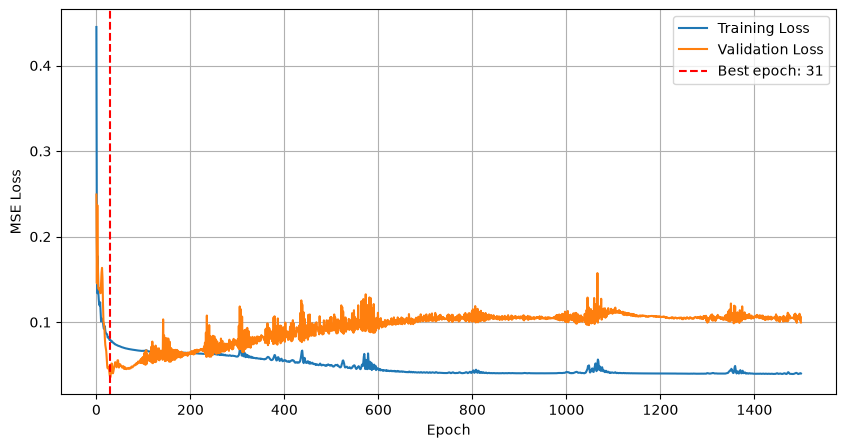

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best epoch: {best_epoch + 1}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()